# Bornholm BikeNodePlanner–OSM overlap

In [1]:
# Run once if your environment is missing packages:
#%pip install geopandas osmnx matplotlib pandas shapely pyogrio

## 1. Setup

In [2]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import shapely
from IPython.display import display

ox.settings.use_cache = True
ox.settings.log_console = True

working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir.parent if working_dir.name == "osm_data_exploration" else working_dir

SAMPLE = "funen"
osm_sample = "Funen, Denmark"

DATA_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"

# output folders
OSM_GRAPH_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_bike_network.graphml"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"
BOUNDARY_PATH = PROJECT_ROOT /  f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_boundary.geojson"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/funen/overlap_clean


## 2. Load both networks


In [3]:
study_edges = gpd.read_file(DATA_DIR / "edges_slope.gpkg")
study_nodes = gpd.read_file(DATA_DIR / "nodes.gpkg")

study_edges = study_edges.loc[study_edges.geometry.notna() & ~study_edges.geometry.is_empty].copy()
study_nodes = study_nodes.loc[study_nodes.geometry.notna() & ~study_nodes.geometry.is_empty].copy()

if OSM_GRAPH_PATH.exists():
    G_osm = ox.load_graphml(OSM_GRAPH_PATH)
    print("Loaded existing OSM GraphML.")
else:
    print("Downloading the OSM network...")
    G_osm = ox.graph_from_place(
        osm_sample, 
        network_type="bike", 
        retain_all=True, 
        simplify=True
    )
    G_osm = ox.project_graph(G_osm)
    OSM_GRAPH_PATH.parent.mkdir(parents=True, exist_ok=True)
    ox.save_graphml(G_osm, OSM_GRAPH_PATH)

STUDY_CRS = "EPSG:25832"

osm_nodes, osm_edges = ox.graph_to_gdfs(G_osm)
osm_nodes = osm_nodes.to_crs(STUDY_CRS)
osm_edges = osm_edges.to_crs(STUDY_CRS)

print(f"Study: {len(study_nodes)} nodes, {len(study_edges)} links")
print(f"OSM: {len(osm_nodes):,} nodes, {len(osm_edges):,} directed edges")

Loaded existing OSM GraphML.
Study: 1014 nodes, 1438 links
OSM: 142,612 nodes, 333,290 directed edges


### If above doesn't work

<class 'networkx.classes.multidigraph.MultiDiGraph'>
Directed: True
CRS: EPSG:32632
Nodes: 142612
Edges: 333290
Saved graph to: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/funen/funen_bike_network.graphml
Saved boundary to: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/funen/funen_boundary.geojson


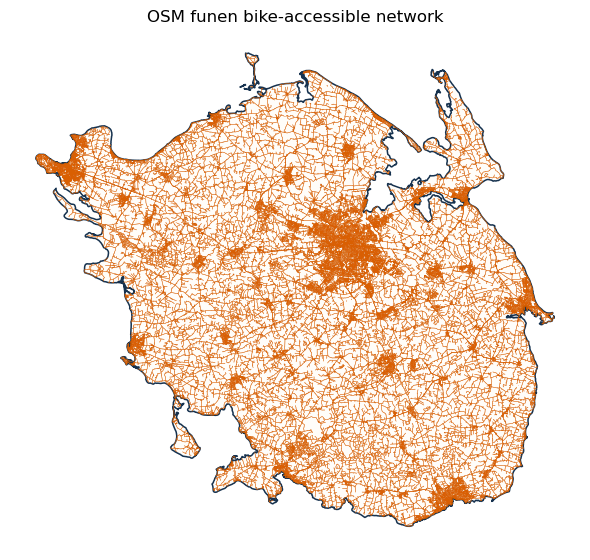

In [4]:
output_dir = Path(f"outputs/{SAMPLE}")
output_dir.mkdir(exist_ok=True)

place_gdf = ox.geocode_to_gdf(osm_sample)
place_poly = place_gdf.geometry.union_all()

# retain_all=True keeps disconnected bike-accessible components.
G = ox.graph_from_polygon(
    place_poly,
    network_type="bike",
    retain_all=True,
    simplify=True,
)

G_proj = ox.project_graph(G)
graph_crs = G_proj.graph["crs"]

print(type(G_proj))
print("Directed:", G_proj.is_directed())
print("CRS:", graph_crs)
print("Nodes:", G_proj.number_of_nodes())
print("Edges:", G_proj.number_of_edges())

ox.io.save_graphml(G_proj, OSM_GRAPH_PATH)
place_gdf.to_file(BOUNDARY_PATH, driver="GeoJSON")

print("Saved graph to:", OSM_GRAPH_PATH)
print("Saved boundary to:", BOUNDARY_PATH)

boundary_proj = place_gdf.to_crs(graph_crs)
nodes, edges = ox.graph_to_gdfs(G_proj)

fig, ax = plt.subplots(figsize=(6, 6))
boundary_proj.plot(ax=ax, facecolor="#fffdf9", edgecolor="#16324f", linewidth=1.1, zorder=1,)
edges.plot(ax=ax, color="#d95f02", linewidth=0.32, alpha=0.82, zorder=2, )
ax.set_title(f"OSM {SAMPLE} bike-accessible network", fontsize=12)
ax.set_axis_off()
fig.tight_layout()
plt.show()

## 3. Calculate overlap

A study line is matched where it lies within the selected distance of OSM bike-accessible linework. Dissolving the nearby OSM geometry prevents its two directed copies from being counted twice.

Compare the processed BikeNodePlanner / knudepunkter network with the OpenStreetMap bike-accessible network.

NOTE: we refer to bikewloops as `STUDY`

The notebook measures overlap in both directions:
- Study coverage by OSM: percentage of the unique knudepunkter line length lying within a given distance of an OSM bike-accessible line.
- OSM coverage by the study network: percentage of the unique OSM bike-network length lying within a given distance of a knudepunkter line.
- Node proximity: percentage of knudepunkter nodes within each distance threshold of OSM linework.
Several tolerances are reported because independently digitized lines rarely coincide exactly. A 20 m tolerance is used for the detailed map and link classification; adjust it below if needed.

In [5]:
# The tolerance in meters for snapping the two networks together. 
# A smaller value may result in fewer overlaps, while a larger value may result in more overlaps.
TOLERANCE_M = 20 

study_network = shapely.union_all(study_edges.geometry.array)

# Keep only OSM edges close enough to influence this comparison.
search_area = study_network.buffer(TOLERANCE_M)
candidate_positions = osm_edges.sindex.query(search_area, predicate="intersects")
osm_edges_near_study = osm_edges.iloc[np.unique(candidate_positions)].copy()
osm_network_near_study = shapely.union_all(osm_edges_near_study.geometry.array)
osm_buffer = osm_network_near_study.buffer(TOLERANCE_M)

matched_geometry = study_network.intersection(osm_buffer)
unmatched_geometry = study_network.difference(osm_buffer)

study_length_m = study_network.length
matched_length_m = matched_geometry.length
unmatched_length_m = unmatched_geometry.length
coverage_pct = 100 * matched_length_m / study_length_m

summary = pd.DataFrame({
    "metric": ["Study length (km)", "Matched length (km)", "Unmatched length (km)", "Coverage (%)"],
    "value": [study_length_m / 1000, matched_length_m / 1000, unmatched_length_m / 1000, coverage_pct],
})
display(summary.round(2))

,metric,value
0,Study length (km),2753.85
1,Matched length (km),2596.73
2,Unmatched length (km),157.12
3,Coverage (%),94.29


## 4. Plot matched and unmatched portions

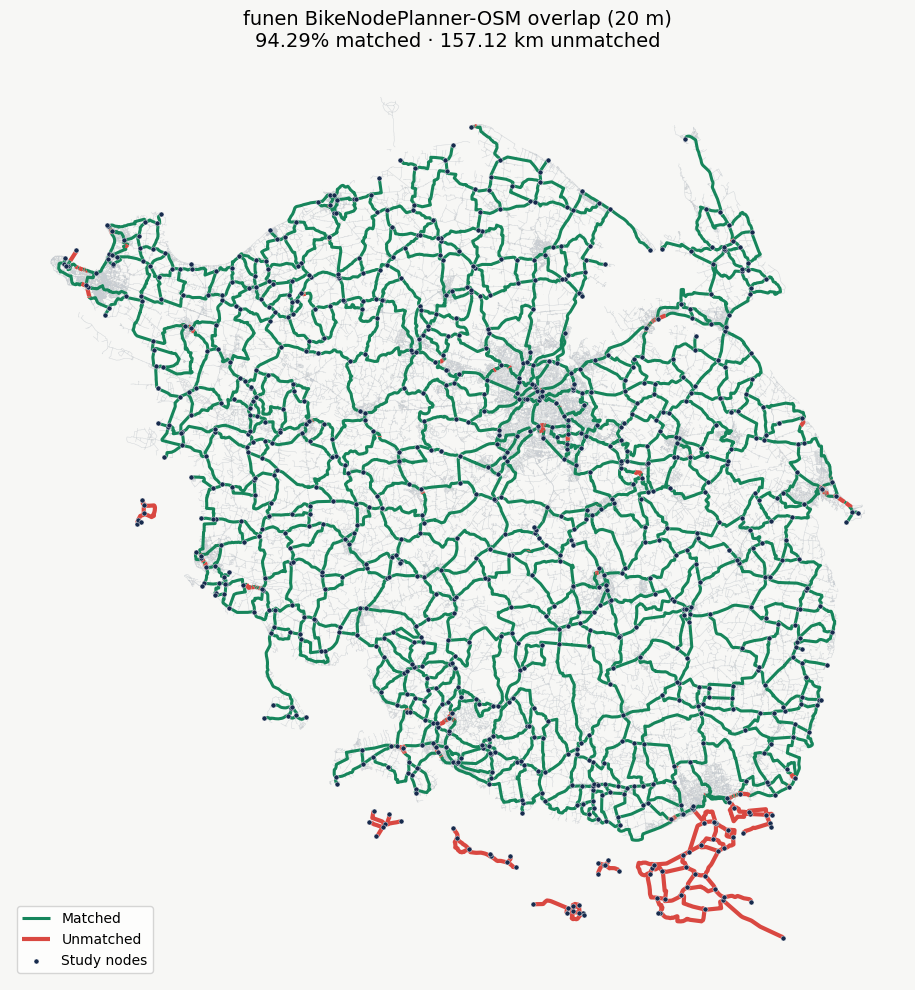

In [6]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5")
osm_edges.plot(ax=ax, color="#c8cdd2", linewidth=0.3, alpha=0.5, zorder=1)

gpd.GeoSeries([matched_geometry], crs=STUDY_CRS).plot(
    ax=ax, color="#16855b", linewidth=2.2, label="Matched", zorder=3
)
if not unmatched_geometry.is_empty:
    gpd.GeoSeries([unmatched_geometry], crs=STUDY_CRS).plot(
        ax=ax, color="#d94841", linewidth=3.0, label="Unmatched", zorder=4
    )
study_nodes.plot(
    ax=ax, color="#172b4d", edgecolor="white", linewidth=0.3,
    markersize=13, label="Study nodes", zorder=5
)

ax.set_title(
    f"{SAMPLE} BikeNodePlanner-OSM overlap ({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · {unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)
ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap.png", bbox_inches="tight")
plt.show()

## 5. Inspect unmatched sections

Each red section retains its original study edge ID. Its midpoint is matched to the nearest OSM edge so that names, highway types, access tags, and distance can be inspected.

In [7]:
def line_parts(geometry):
    if geometry is None or geometry.is_empty:
        return
    if geometry.geom_type == "LineString":
        yield geometry
    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            yield from line_parts(part)

records = []
for _, edge in study_edges.iterrows():
    for geometry in line_parts(edge.geometry.difference(osm_buffer)):
        if geometry.length >= 1:  # ignore sub-metre precision fragments
            records.append({
                "edge_id": edge["edge_id"],
                "node_start": edge["node_start"],
                "node_end": edge["node_end"],
                "unmatched_m": geometry.length,
                "geometry": geometry,
            })

unmatched = gpd.GeoDataFrame(records, geometry="geometry", crs=STUDY_CRS)
unmatched.insert(0, "segment_id", np.arange(1, len(unmatched) + 1))

osm_lookup = osm_edges.reset_index()
tag_columns = [
    column for column in ["u", "v", "key", "osmid", "name", "highway", "bicycle", "access", "surface", "geometry"]
    if column in osm_lookup.columns
]
midpoints = gpd.GeoDataFrame(
    unmatched[["segment_id"]],
    geometry=unmatched.geometry.interpolate(0.5, normalized=True),
    crs=STUDY_CRS,
)
nearest = gpd.sjoin_nearest(
    midpoints, osm_lookup[tag_columns], how="left", distance_col="distance_to_osm_m"
)
nearest = (
    nearest.sort_values("distance_to_osm_m")
    .drop_duplicates("segment_id")
    .drop(columns=["geometry", "index_right"], errors="ignore")
)
unmatched = unmatched.merge(nearest, on="segment_id", how="left")

columns = [
    column for column in ["segment_id", "edge_id", "node_start", "node_end", "unmatched_m",
                          "distance_to_osm_m", "osmid", "name", "highway", "bicycle", "access"]
    if column in unmatched.columns
]
display(unmatched[columns].sort_values("unmatched_m", ascending=False).round(2))

,segment_id,edge_id,node_start,node_end,unmatched_m,distance_to_osm_m,osmid,name,highway,access
7,8,7,4,39,6648.87,10983.90,726943784,NaN,path,NaN
0,1,0,0,1,5720.40,8468.11,25548560,Lehnskov Strand,unclassified,NaN
63,64,79,59,60,3534.06,1552.35,726943784,NaN,path,NaN
18,19,18,10,14,3501.11,2342.60,164754247,Lehnskov Strand,service,NaN
36,37,43,29,31,3447.78,7454.45,108699035,Langemarken,unclassified,NaN
...,...,...,...,...,...,...,...,...,...,...
206,207,793,540,541,2.60,20.82,143447625,NaN,service,NaN
203,204,780,530,541,2.19,20.61,150014432,NaN,service,NaN
185,186,605,414,636,2.03,20.74,984760681,NaN,path,NaN
177,178,604,413,414,1.62,20.59,25711569,Wørishøffersgade,residential,NaN


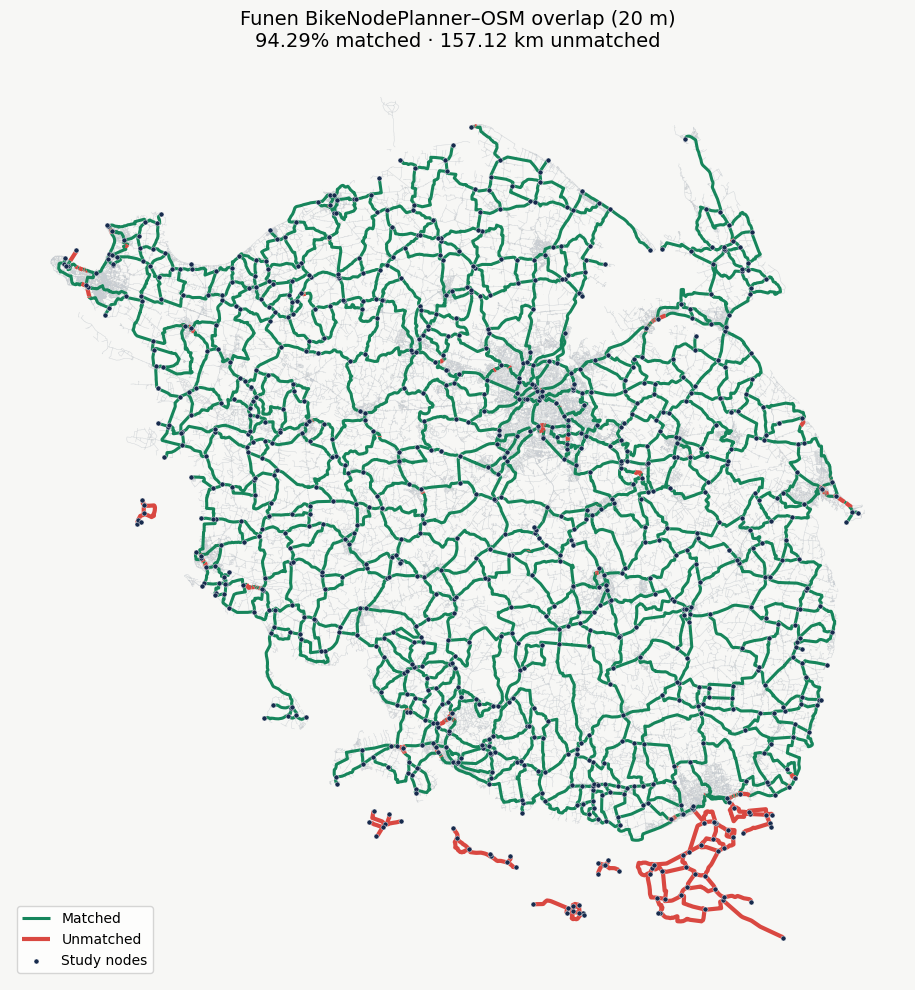

In [8]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5",)

# OSM network.
osm_edges.plot(
    ax=ax,
    color="#c8cdd2",
    linewidth=0.3,
    alpha=0.5,
    zorder=1,
)

# Matched study geometry.'
gpd.GeoSeries(
    [matched_geometry],
    crs=STUDY_CRS,
).plot(
    ax=ax,
    color="#16855b",
    linewidth=2.2,
    label="Matched",
    zorder=3,
)

# Unmatched study segments.
if not unmatched.empty:
    unmatched.plot(
        ax=ax,
        color="#d94841",
        linewidth=3,
        label="Unmatched",
        zorder=4,
    )

# Study nodes.
study_nodes.plot(
    ax=ax,
    color="#172b4d",
    edgecolor="white",
    linewidth=0.3,
    markersize=13,
    label="Study nodes",
    zorder=5,
)

ax.set_title(
    f"{SAMPLE.title()} BikeNodePlanner–OSM overlap "
    f"({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · "
    f"{unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)

ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap_numbered.png", bbox_inches="tight",)
plt.show()

# Langeland

In [9]:
SAMPLE = "longland"
osm_sample = "Langeland, Denmark"

DATA_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"

# output folders
OSM_GRAPH_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_bike_network.graphml"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"
BOUNDARY_PATH = PROJECT_ROOT /  f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_boundary.geojson"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

study_edges = gpd.read_file(DATA_DIR / "edges_slope.gpkg")
study_nodes = gpd.read_file(DATA_DIR / "nodes.gpkg")

study_edges = study_edges.loc[study_edges.geometry.notna() & ~study_edges.geometry.is_empty].copy()
study_nodes = study_nodes.loc[study_nodes.geometry.notna() & ~study_nodes.geometry.is_empty].copy()

if OSM_GRAPH_PATH.exists():
    G_osm = ox.load_graphml(OSM_GRAPH_PATH)
    print("Loaded existing OSM GraphML.")
else:
    print("Downloading the OSM network...")
    G_osm = ox.graph_from_place(
        osm_sample, 
        network_type="bike", 
        retain_all=True, 
        simplify=True
    )
    G_osm = ox.project_graph(G_osm)
    OSM_GRAPH_PATH.parent.mkdir(parents=True, exist_ok=True)
    ox.save_graphml(G_osm, OSM_GRAPH_PATH)

STUDY_CRS = "EPSG:25832"

osm_nodes, osm_edges = ox.graph_to_gdfs(G_osm)
osm_nodes = osm_nodes.to_crs(STUDY_CRS)
osm_edges = osm_edges.to_crs(STUDY_CRS)

print(f"Study: {len(study_nodes)} nodes, {len(study_edges)} links")
print(f"OSM: {len(osm_nodes):,} nodes, {len(osm_edges):,} directed edges")


Loaded existing OSM GraphML.
Study: 102 nodes, 130 links
OSM: 7,950 nodes, 18,435 directed edges


In [10]:
# The tolerance in meters for snapping the two networks together. 
# A smaller value may result in fewer overlaps, while a larger value may result in more overlaps.
TOLERANCE_M = 20 

study_network = shapely.union_all(study_edges.geometry.array)

# Keep only OSM edges close enough to influence this comparison.
search_area = study_network.buffer(TOLERANCE_M)
candidate_positions = osm_edges.sindex.query(search_area, predicate="intersects")
osm_edges_near_study = osm_edges.iloc[np.unique(candidate_positions)].copy()
osm_network_near_study = shapely.union_all(osm_edges_near_study.geometry.array)
osm_buffer = osm_network_near_study.buffer(TOLERANCE_M)

matched_geometry = study_network.intersection(osm_buffer)
unmatched_geometry = study_network.difference(osm_buffer)

study_length_m = study_network.length
matched_length_m = matched_geometry.length
unmatched_length_m = unmatched_geometry.length
coverage_pct = 100 * matched_length_m / study_length_m

summary = pd.DataFrame({
    "metric": ["Study length (km)", "Matched length (km)", "Unmatched length (km)", "Coverage (%)"],
    "value": [study_length_m / 1000, matched_length_m / 1000, unmatched_length_m / 1000, coverage_pct],
})
display(summary.round(2))

,metric,value
0,Study length (km),269.35
1,Matched length (km),257.22
2,Unmatched length (km),12.13
3,Coverage (%),95.50


In [11]:
def line_parts(geometry):
    if geometry is None or geometry.is_empty:
        return
    if geometry.geom_type == "LineString":
        yield geometry
    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            yield from line_parts(part)

records = []
for _, edge in study_edges.iterrows():
    for geometry in line_parts(edge.geometry.difference(osm_buffer)):
        if geometry.length >= 1:  # ignore sub-metre precision fragments
            records.append({
                "edge_id": edge["edge_id"],
                "node_start": edge["node_start"],
                "node_end": edge["node_end"],
                "unmatched_m": geometry.length,
                "geometry": geometry,
            })

unmatched = gpd.GeoDataFrame(records, geometry="geometry", crs=STUDY_CRS)
unmatched.insert(0, "segment_id", np.arange(1, len(unmatched) + 1))

osm_lookup = osm_edges.reset_index()
tag_columns = [
    column for column in ["u", "v", "key", "osmid", "name", "highway", "bicycle", "access", "surface", "geometry"]
    if column in osm_lookup.columns
]
midpoints = gpd.GeoDataFrame(
    unmatched[["segment_id"]],
    geometry=unmatched.geometry.interpolate(0.5, normalized=True),
    crs=STUDY_CRS,
)
nearest = gpd.sjoin_nearest(
    midpoints, osm_lookup[tag_columns], how="left", distance_col="distance_to_osm_m"
)
nearest = (
    nearest.sort_values("distance_to_osm_m")
    .drop_duplicates("segment_id")
    .drop(columns=["geometry", "index_right"], errors="ignore")
)
unmatched = unmatched.merge(nearest, on="segment_id", how="left")

columns = [
    column for column in ["segment_id", "edge_id", "node_start", "node_end", "unmatched_m",
                          "distance_to_osm_m", "osmid", "name", "highway", "bicycle", "access"]
    if column in unmatched.columns
]
display(unmatched[columns].sort_values("unmatched_m", ascending=False).round(2))

,segment_id,edge_id,node_start,node_end,unmatched_m,distance_to_osm_m,osmid,name,highway,access
10,11,72,55,68,6319.84,2892.90,26520613,Havnepladsen,unclassified,NaN
4,5,58,44,46,2009.02,4986.99,"[106973438, 621732139, 204904022]",Faarevejle Alle,"[service, track]",NaN
0,1,54,41,42,1368.37,4579.95,109939386,Langøvej,track,NaN
1,2,55,41,43,1064.70,3946.96,"[204904022, 621732139, 106973438]",Faarevejle Alle,"[service, track]",NaN
3,4,57,44,45,863.00,5167.03,"[204904022, 621732139, 106973438]",Faarevejle Alle,"[service, track]",NaN
2,3,56,41,44,302.96,4616.53,"[204904022, 621732139, 106973438]",Faarevejle Alle,"[service, track]",NaN
5,6,63,49,53,100.25,23.44,26520716,NaN,track,NaN
6,7,69,53,55,31.92,31.53,"[666167797, 45818639]",Ringvejen,tertiary,NaN
9,10,71,55,56,28.99,28.13,464725018,NaN,cycleway,NaN
12,13,84,63,64,17.93,28.87,204940349,Bukkeskovvej,unclassified,NaN


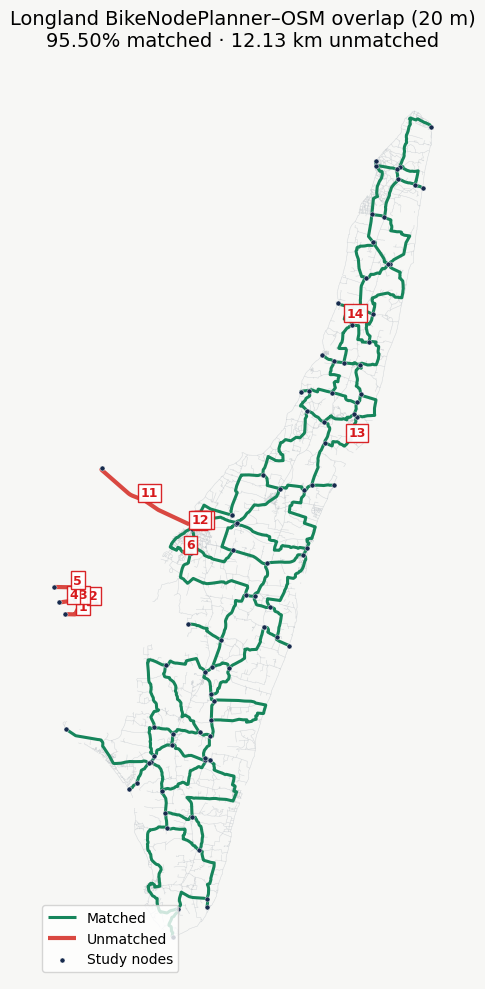

In [12]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5",)

# OSM network.
osm_edges.plot(
    ax=ax,
    color="#c8cdd2",
    linewidth=0.3,
    alpha=0.5,
    zorder=1,
)

# Matched study geometry.
gpd.GeoSeries(
    [matched_geometry],
    crs=STUDY_CRS,
).plot(
    ax=ax,
    color="#16855b",
    linewidth=2.2,
    label="Matched",
    zorder=3,
)

# Unmatched study segments.
if not unmatched.empty:
    unmatched.plot(
        ax=ax,
        color="#d94841",
        linewidth=3,
        label="Unmatched",
        zorder=4,
    )

    # Add a number beside each unmatched segment.
    for _, segment in unmatched.iterrows():
        label_point = segment.geometry.interpolate(0.5, normalized=True,)

        ax.annotate(
            text=str(segment["segment_id"]),
            xy=(label_point.x, label_point.y,),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color="#d7191c",
            ha="center",
            va="center",
            bbox={
                "boxstyle": "square,pad=0.2",
                "facecolor": "white",
                "edgecolor": "#d7191c",
                "linewidth": 1,
                "alpha": 0.95,
            },
            zorder=6,
        )

# Study nodes.
study_nodes.plot(
    ax=ax,
    color="#172b4d",
    edgecolor="white",
    linewidth=0.3,
    markersize=13,
    label="Study nodes",
    zorder=5,
)

ax.set_title(
    f"{SAMPLE.title()} BikeNodePlanner–OSM overlap "
    f"({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · "
    f"{unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)

ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap_numbered.png", bbox_inches="tight",)
plt.show()

# Jylland

In [13]:
SAMPLE = "jutland"
osm_sample = "Jylland, Denmark"

DATA_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"

# output folders
OSM_GRAPH_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_bike_network.graphml"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"
BOUNDARY_PATH = PROJECT_ROOT /  f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_boundary.geojson"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

study_edges = gpd.read_file(DATA_DIR / "edges_slope.gpkg")
study_nodes = gpd.read_file(DATA_DIR / "nodes.gpkg")

study_edges = study_edges.loc[study_edges.geometry.notna() & ~study_edges.geometry.is_empty].copy()
study_nodes = study_nodes.loc[study_nodes.geometry.notna() & ~study_nodes.geometry.is_empty].copy()

if OSM_GRAPH_PATH.exists():
    G_osm = ox.load_graphml(OSM_GRAPH_PATH)
    print("Loaded existing OSM GraphML.")
else:
    print("Downloading the OSM network...")
    G_osm = ox.graph_from_place(
        osm_sample, 
        network_type="bike", 
        retain_all=True, 
        simplify=True
    )
    G_osm = ox.project_graph(G_osm)
    OSM_GRAPH_PATH.parent.mkdir(parents=True, exist_ok=True)
    ox.save_graphml(G_osm, OSM_GRAPH_PATH)

STUDY_CRS = "EPSG:25832"

osm_nodes, osm_edges = ox.graph_to_gdfs(G_osm)
osm_nodes = osm_nodes.to_crs(STUDY_CRS)
osm_edges = osm_edges.to_crs(STUDY_CRS)

print(f"Study: {len(study_nodes)} nodes, {len(study_edges)} links")
print(f"OSM: {len(osm_nodes):,} nodes, {len(osm_edges):,} directed edges")


/Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/.pixi/envs/default/lib/python3.12/site-packages/osmnx/_overpass.py:271: UserWarning: This area is 16 times your configured Overpass max query area size. It will automatically be divided up into multiple sub-queries accordingly. This may take a long time.
  multi_poly_proj = utils_geo._consolidate_subdivide_geometry(poly_proj)


ConnectionError: HTTPSConnectionPool(host='overpass-api.de', port=443): Max retries exceeded with url: /api/interpreter (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x37a5a7680>: Failed to establish a new connection: [Errno 61] Connection refused'))

In [ ]:
# The tolerance in meters for snapping the two networks together. 
# A smaller value may result in fewer overlaps, while a larger value may result in more overlaps.
TOLERANCE_M = 20 

study_network = shapely.union_all(study_edges.geometry.array)

# Keep only OSM edges close enough to influence this comparison.
search_area = study_network.buffer(TOLERANCE_M)
candidate_positions = osm_edges.sindex.query(search_area, predicate="intersects")
osm_edges_near_study = osm_edges.iloc[np.unique(candidate_positions)].copy()
osm_network_near_study = shapely.union_all(osm_edges_near_study.geometry.array)
osm_buffer = osm_network_near_study.buffer(TOLERANCE_M)

matched_geometry = study_network.intersection(osm_buffer)
unmatched_geometry = study_network.difference(osm_buffer)

study_length_m = study_network.length
matched_length_m = matched_geometry.length
unmatched_length_m = unmatched_geometry.length
coverage_pct = 100 * matched_length_m / study_length_m

summary = pd.DataFrame({
    "metric": ["Study length (km)", "Matched length (km)", "Unmatched length (km)", "Coverage (%)"],
    "value": [study_length_m / 1000, matched_length_m / 1000, unmatched_length_m / 1000, coverage_pct],
})
display(summary.round(2))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5")
osm_edges.plot(ax=ax, color="#c8cdd2", linewidth=0.3, alpha=0.5, zorder=1)

gpd.GeoSeries([matched_geometry], crs=STUDY_CRS).plot(
    ax=ax, color="#16855b", linewidth=2.2, label="Matched", zorder=3
)
if not unmatched_geometry.is_empty:
    gpd.GeoSeries([unmatched_geometry], crs=STUDY_CRS).plot(
        ax=ax, color="#d94841", linewidth=3.0, label="Unmatched", zorder=4
    )
study_nodes.plot(
    ax=ax, color="#172b4d", edgecolor="white", linewidth=0.3,
    markersize=13, label="Study nodes", zorder=5
)

ax.set_title(
    f"{SAMPLE} BikeNodePlanner-OSM overlap ({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · {unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)
ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap.png", bbox_inches="tight")
plt.show()

In [ ]:
def line_parts(geometry):
    if geometry is None or geometry.is_empty:
        return
    if geometry.geom_type == "LineString":
        yield geometry
    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            yield from line_parts(part)

records = []
for _, edge in study_edges.iterrows():
    for geometry in line_parts(edge.geometry.difference(osm_buffer)):
        if geometry.length >= 1:  # ignore sub-metre precision fragments
            records.append({
                "edge_id": edge["edge_id"],
                "node_start": edge["node_start"],
                "node_end": edge["node_end"],
                "unmatched_m": geometry.length,
                "geometry": geometry,
            })

unmatched = gpd.GeoDataFrame(records, geometry="geometry", crs=STUDY_CRS)
unmatched.insert(0, "segment_id", np.arange(1, len(unmatched) + 1))

osm_lookup = osm_edges.reset_index()
tag_columns = [
    column for column in ["u", "v", "key", "osmid", "name", "highway", "bicycle", "access", "surface", "geometry"]
    if column in osm_lookup.columns
]
midpoints = gpd.GeoDataFrame(
    unmatched[["segment_id"]],
    geometry=unmatched.geometry.interpolate(0.5, normalized=True),
    crs=STUDY_CRS,
)
nearest = gpd.sjoin_nearest(
    midpoints, osm_lookup[tag_columns], how="left", distance_col="distance_to_osm_m"
)
nearest = (
    nearest.sort_values("distance_to_osm_m")
    .drop_duplicates("segment_id")
    .drop(columns=["geometry", "index_right"], errors="ignore")
)
unmatched = unmatched.merge(nearest, on="segment_id", how="left")

columns = [
    column for column in ["segment_id", "edge_id", "node_start", "node_end", "unmatched_m",
                          "distance_to_osm_m", "osmid", "name", "highway", "bicycle", "access"]
    if column in unmatched.columns
]
display(unmatched[columns].sort_values("unmatched_m", ascending=False).round(2))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5",)

# OSM network.
osm_edges.plot(
    ax=ax,
    color="#c8cdd2",
    linewidth=0.3,
    alpha=0.5,
    zorder=1,
)

# Matched study geometry.'
gpd.GeoSeries(
    [matched_geometry],
    crs=STUDY_CRS,
).plot(
    ax=ax,
    color="#16855b",
    linewidth=2.2,
    label="Matched",
    zorder=3,
)

# Unmatched study segments.
if not unmatched.empty:
    unmatched.plot(
        ax=ax,
        color="#d94841",
        linewidth=3,
        label="Unmatched",
        zorder=4,
    )

# Study nodes.
study_nodes.plot(
    ax=ax,
    color="#172b4d",
    edgecolor="white",
    linewidth=0.3,
    markersize=13,
    label="Study nodes",
    zorder=5,
)

ax.set_title(
    f"{SAMPLE.title()} BikeNodePlanner–OSM overlap "
    f"({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · "
    f"{unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)

ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap_numbered.png", bbox_inches="tight",)
plt.show()

In [ ]:
SAMPLE = "lollandfalster"
osm_sample = "Lollandfalster, Denmark"

DATA_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"

# output folders
OSM_GRAPH_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_bike_network.graphml"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"
BOUNDARY_PATH = PROJECT_ROOT /  f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_boundary.geojson"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

study_edges = gpd.read_file(DATA_DIR / "edges_slope.gpkg")
study_nodes = gpd.read_file(DATA_DIR / "nodes.gpkg")

study_edges = study_edges.loc[study_edges.geometry.notna() & ~study_edges.geometry.is_empty].copy()
study_nodes = study_nodes.loc[study_nodes.geometry.notna() & ~study_nodes.geometry.is_empty].copy()

if OSM_GRAPH_PATH.exists():
    G_osm = ox.load_graphml(OSM_GRAPH_PATH)
    print("Loaded existing OSM GraphML.")
else:
    print("Downloading the OSM network...")
    G_osm = ox.graph_from_place(
        osm_sample, 
        network_type="bike", 
        retain_all=True, 
        simplify=True
    )
    G_osm = ox.project_graph(G_osm)
    OSM_GRAPH_PATH.parent.mkdir(parents=True, exist_ok=True)
    ox.save_graphml(G_osm, OSM_GRAPH_PATH)

STUDY_CRS = "EPSG:25832"

osm_nodes, osm_edges = ox.graph_to_gdfs(G_osm)
osm_nodes = osm_nodes.to_crs(STUDY_CRS)
osm_edges = osm_edges.to_crs(STUDY_CRS)

print(f"Study: {len(study_nodes)} nodes, {len(study_edges)} links")
print(f"OSM: {len(osm_nodes):,} nodes, {len(osm_edges):,} directed edges")

In [ ]:
# The tolerance in meters for snapping the two networks together. 
# A smaller value may result in fewer overlaps, while a larger value may result in more overlaps.
TOLERANCE_M = 20 

study_network = shapely.union_all(study_edges.geometry.array)

# Keep only OSM edges close enough to influence this comparison.
search_area = study_network.buffer(TOLERANCE_M)
candidate_positions = osm_edges.sindex.query(search_area, predicate="intersects")
osm_edges_near_study = osm_edges.iloc[np.unique(candidate_positions)].copy()
osm_network_near_study = shapely.union_all(osm_edges_near_study.geometry.array)
osm_buffer = osm_network_near_study.buffer(TOLERANCE_M)

matched_geometry = study_network.intersection(osm_buffer)
unmatched_geometry = study_network.difference(osm_buffer)

study_length_m = study_network.length
matched_length_m = matched_geometry.length
unmatched_length_m = unmatched_geometry.length
coverage_pct = 100 * matched_length_m / study_length_m

summary = pd.DataFrame({
    "metric": ["Study length (km)", "Matched length (km)", "Unmatched length (km)", "Coverage (%)"],
    "value": [study_length_m / 1000, matched_length_m / 1000, unmatched_length_m / 1000, coverage_pct],
})
display(summary.round(2))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5")
osm_edges.plot(ax=ax, color="#c8cdd2", linewidth=0.3, alpha=0.5, zorder=1)

gpd.GeoSeries([matched_geometry], crs=STUDY_CRS).plot(
    ax=ax, color="#16855b", linewidth=2.2, label="Matched", zorder=3
)
if not unmatched_geometry.is_empty:
    gpd.GeoSeries([unmatched_geometry], crs=STUDY_CRS).plot(
        ax=ax, color="#d94841", linewidth=3.0, label="Unmatched", zorder=4
    )
study_nodes.plot(
    ax=ax, color="#172b4d", edgecolor="white", linewidth=0.3,
    markersize=13, label="Study nodes", zorder=5
)

ax.set_title(
    f"{SAMPLE} BikeNodePlanner-OSM overlap ({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · {unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)
ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap.png", bbox_inches="tight")
plt.show()

In [ ]:
def line_parts(geometry):
    if geometry is None or geometry.is_empty:
        return
    if geometry.geom_type == "LineString":
        yield geometry
    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            yield from line_parts(part)

records = []
for _, edge in study_edges.iterrows():
    for geometry in line_parts(edge.geometry.difference(osm_buffer)):
        if geometry.length >= 1:  # ignore sub-metre precision fragments
            records.append({
                "edge_id": edge["edge_id"],
                "node_start": edge["node_start"],
                "node_end": edge["node_end"],
                "unmatched_m": geometry.length,
                "geometry": geometry,
            })

unmatched = gpd.GeoDataFrame(records, geometry="geometry", crs=STUDY_CRS)
unmatched.insert(0, "segment_id", np.arange(1, len(unmatched) + 1))

osm_lookup = osm_edges.reset_index()
tag_columns = [
    column for column in ["u", "v", "key", "osmid", "name", "highway", "bicycle", "access", "surface", "geometry"]
    if column in osm_lookup.columns
]
midpoints = gpd.GeoDataFrame(
    unmatched[["segment_id"]],
    geometry=unmatched.geometry.interpolate(0.5, normalized=True),
    crs=STUDY_CRS,
)
nearest = gpd.sjoin_nearest(
    midpoints, osm_lookup[tag_columns], how="left", distance_col="distance_to_osm_m"
)
nearest = (
    nearest.sort_values("distance_to_osm_m")
    .drop_duplicates("segment_id")
    .drop(columns=["geometry", "index_right"], errors="ignore")
)
unmatched = unmatched.merge(nearest, on="segment_id", how="left")

columns = [
    column for column in ["segment_id", "edge_id", "node_start", "node_end", "unmatched_m",
                          "distance_to_osm_m", "osmid", "name", "highway", "bicycle", "access"]
    if column in unmatched.columns
]
display(unmatched[columns].sort_values("unmatched_m", ascending=False).round(2))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#f7f7f5",)

# OSM network.
osm_edges.plot(
    ax=ax,
    color="#c8cdd2",
    linewidth=0.3,
    alpha=0.5,
    zorder=1,
)

# Matched study geometry.
gpd.GeoSeries(
    [matched_geometry],
    crs=STUDY_CRS,
).plot(
    ax=ax,
    color="#16855b",
    linewidth=2.2,
    label="Matched",
    zorder=3,
)

# Unmatched study segments.
if not unmatched.empty:
    unmatched.plot(
        ax=ax,
        color="#d94841",
        linewidth=3,
        label="Unmatched",
        zorder=4,
    )

    # Add a number beside each unmatched segment.
    for _, segment in unmatched.iterrows():
        label_point = segment.geometry.interpolate(0.5, normalized=True,)

        ax.annotate(
            text=str(segment["segment_id"]),
            xy=(label_point.x, label_point.y,),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color="#d7191c",
            ha="center",
            va="center",
            bbox={
                "boxstyle": "square,pad=0.2",
                "facecolor": "white",
                "edgecolor": "#d7191c",
                "linewidth": 1,
                "alpha": 0.95,
            },
            zorder=6,
        )

# Study nodes.
study_nodes.plot(
    ax=ax,
    color="#172b4d",
    edgecolor="white",
    linewidth=0.3,
    markersize=13,
    label="Study nodes",
    zorder=5,
)

ax.set_title(
    f"{SAMPLE.title()} BikeNodePlanner–OSM overlap "
    f"({TOLERANCE_M} m)\n"
    f"{coverage_pct:.2f}% matched · "
    f"{unmatched_length_m / 1000:.2f} km unmatched",
    fontsize=14,
)

ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{SAMPLE}_overlap_numbered.png", bbox_inches="tight",)
plt.show()